# 03 · GraphRAG: cuando la respuesta está repartida entre varios documentos

**Idea:** «¿Quién aprueba los viajes internacionales de la jefa del equipo que mantiene la pasarela de pagos?» no vive en ningún
documento. Hay que **encadenar** 3: quién mantiene PayHub → a quién reporta esa persona → quién aprueba viajes.
La búsqueda por similitud trae documentos *parecidos a la pregunta*, no la **cadena de relaciones**.

En este notebook:
1. Conviertes los documentos en un **grafo de conocimiento** (aquí con tripletas escritas a mano; en producción las extrae un LLM).
2. Recuperas por **recorrido del grafo** desde las entidades de la pregunta.
3. Mides si cada estrategia **junta todos los documentos que la respuesta necesita**.

## Glosario · GraphRAG

Lo que necesitas para leer este notebook (puedes volver aquí cuando una palabra no te suene):

- **Embedding:** lista de números que representa el *significado* de un texto; textos con sentido parecido quedan «cerca», aunque no compartan palabras.
- **Similitud coseno:** qué tan cerca están dos embeddings (cerca de 1 = parecidos; cerca de 0 = nada que ver).
- **BM25:** puntaje por *palabras exactas*: cuenta qué documentos contienen las palabras de la pregunta y valora más las raras (`ERR-5012`) que las comunes. No entiende sinónimos; si no comparte ninguna palabra, no devuelve nada. Su puntaje no tiene tope y no es comparable con el coseno.
- **Top-k:** los *k* primeros resultados del ranking (top-3 = los tres mejores).
- **Híbrido calibrado:** mezcla `α · coseno + (1 − α) · BM25` (ambos llevados a 0–1), con α elegido en el set de ajuste. Se explica en el notebook 01; aquí se reutiliza.
- **Grafo:** nodos (entidades, como `PayHub` o `Rosa Quispe`) unidos por aristas (relaciones, como «lidera» o «aprueba»).
- **Tripleta:** `(sujeto, relación, objeto)`; cada una es una arista y recuerda de qué documento sale.
- **Multi-hop:** encadenar varios saltos entre entidades para llegar a un dato que ningún documento tiene entero.
- **Puente:** el dato intermedio que la pregunta no nombra, pero sin el cual no se llega a la respuesta.
- **Cobertura / precisión:** fracción de los documentos necesarios que quedan en el contexto / qué parte del contexto era necesaria.
- **Texto top-3 / top-6:** los 3 o 6 mejores documentos del híbrido de texto.

## Los datos de este notebook (qué es cada campo)

| Conjunto | Qué es | Campos de cada elemento |
|---|---|---|
| `DOCS` | los mismos 42 documentos del notebook 01; aquí importan los `E##` (entidades) | `(id, título, texto, tipo)` |
| `MULTIHOP` y `MULTIHOP_PUENTE` | preguntas que exigen juntar varios documentos (6 nombran las entidades; 3 tienen «puente oculto») | `(pregunta, documentos_necesarios, respuesta_esperada)` |
| `TRIPLES` | el grafo escrito a mano: una arista por tupla | `(sujeto, relación, objeto, doc_fuente)`. **doc_fuente**: de qué documento sale la relación, para citar cada salto. |

In [1]:
import importlib.util, subprocess, sys

for paquete, modulo in [("rank-bm25", "rank_bm25"), ("sentence-transformers", "sentence_transformers"), ("networkx", "networkx"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", paquete])
print("Entorno listo")

Entorno listo


In [2]:
#@title Datos sintéticos de «Andina Retail» (no necesitas leer esta celda) { display-mode: "form" }
"""Corpus sintético de «Andina Retail» para los notebooks del taller.

Se inserta tal cual en cada notebook (celda oculta con #@title), así cada uno corre solo en Colab.
Todo es inventado: las métricas que salgan ilustran un criterio, no miden producción.
"""

# ---------------------------------------------------------------- documentos
# ESQUEMA · DOCS (el corpus: 42 «documentos» cortos, cada uno es una tupla de 4 campos)
#   (id, título, texto, tipo)
#   id     código único del documento. La letra dice de qué familia es:
#            P = política interna · T = técnico (código exacto) · D = «distractor» (código casi idéntico a uno T)
#            E = entidades y relaciones (personas, equipos, sistemas; sirven para el notebook de grafo)
#   título nombre corto del documento (se indexa junto con el texto).
#   texto  contenido que se busca y que se le entregaría al modelo (1–3 frases).
#   tipo   categoría temática: politica · tecnico · producto · contrato · organizacion · incidente.
#          No se usa para buscar; solo describe el documento.
# Ejemplo: ("P01", "Vacaciones", "Los colaboradores acumulan 30 días…", "politica")
DOCS = [
    # Políticas (preguntas semánticas, con paráfrasis)
    ("P01", "Vacaciones", "Los colaboradores acumulan 30 días calendario de descanso remunerado por año de servicio. El periodo puede fraccionarse en bloques de mínimo 7 días con aprobación del jefe directo.", "politica"),
    ("P02", "Teletrabajo", "Se permite el trabajo remoto hasta tres días por semana. El día presencial obligatorio es el martes. Se requiere conexión VPN corporativa y equipo entregado por la empresa.", "politica"),
    ("P03", "Devoluciones", "El cliente puede devolver un producto dentro de 30 días desde la compra, con boleta y empaque sellado. Los productos de electrónica tienen un plazo de 15 días. El reembolso se realiza al mismo medio de pago.", "politica"),
    ("P04", "Viáticos", "Los gastos de viaje se reembolsan con comprobante dentro de 10 días hábiles. El tope diario de alimentación es 120 soles. Los viajes internacionales requieren aprobación de la gerencia del área.", "politica"),
    ("P05", "Licencias", "La licencia por paternidad es de 10 días calendario y la de maternidad de 98 días. Se solicita a Recursos Humanos con el certificado médico correspondiente.", "politica"),
    ("P06", "Seguridad de la información", "Las claves de acceso deben tener 14 caracteres y cambiarse cada 90 días. Todo acceso a sistemas internos exige verificación en dos pasos (MFA). Está prohibido compartir credenciales.", "politica"),
    ("P07", "Código de conducta: obsequios", "No se aceptan obsequios, invitaciones ni atenciones de proveedores con valor mayor a 100 soles. Todo ofrecimiento debe reportarse al área de Cumplimiento.", "politica"),
    ("P08", "Proceso de compras", "Toda compra sobre 5,000 soles exige tres cotizaciones comparables y la aprobación del comité de compras. Las compras menores se tramitan con una sola cotización.", "politica"),
    ("P09", "Capacitación", "Cada colaborador dispone de un presupuesto anual de 2,000 soles para cursos, certificaciones y congresos, previa autorización de su jefe directo.", "politica"),
    ("P10", "Horario y tardanzas", "El horario de oficina es de 9:00 a 18:00. Las tardanzas acumuladas superiores a 60 minutos en el mes se descuentan de la remuneración y tres tardanzas generan una amonestación escrita.", "politica"),
    # Técnicos con códigos exactos (palabra clave)
    ("T01", "ERR-5021 pasarela de pagos", "ERR-5021: fallo de conexión con la pasarela de pagos PayHub. Reintentar tras 30 segundos; si persiste, escalar al equipo Pagos con el identificador de la transacción.", "tecnico"),
    ("T02", "ERR-7714 inventario", "ERR-7714: inventario desincronizado entre la tienda y el almacén central. Ejecutar la reconciliación nocturna con el job REC-NIGHT-02 y validar el stock al día siguiente.", "tecnico"),
    ("T03", "ERR-1003 sesión", "ERR-1003: el token de sesión de la aplicación móvil expiró. El usuario debe volver a iniciar sesión; no requiere escalamiento.", "tecnico"),
    ("T04", "SKU-48213 licuadora", "SKU-48213: Licuadora Oster ProBlend de 1.5 litros, línea hogar. Garantía de 24 meses con boleta de compra.", "producto"),
    ("T05", "SKU-90117 laptop", "SKU-90117: Laptop Lenovo IdeaPad 5 con 16 GB de RAM, línea electrónica. Garantía de 12 meses con boleta de compra.", "producto"),
    ("T06", "SKU-33502 refrigeradora", "SKU-33502: Refrigeradora Samsung de 380 litros con tecnología inverter, línea blanca. Garantía de 36 meses con boleta de compra.", "producto"),
    ("T07", "RB-204 certificados TLS", "RB-204: procedimiento para rotar los certificados TLS del balanceador. Se ejecuta en ventana de mantenimiento, con aprobación del responsable de Infraestructura y validación posterior de los endpoints.", "tecnico"),
    ("T08", "Contrato CT-2024-0087", "CT-2024-0087: contrato de transporte con el proveedor Logística Andes, vigente hasta diciembre de 2026, con penalidad del 2% por entregas tardías.", "contrato"),
    # Distractores: códigos casi idénticos, como en cualquier catálogo o log real
    ("D01", "ERR-5012 pasarela", "ERR-5012: tiempo de espera agotado al consultar el estado de un pago en la pasarela de pagos PayHub. Reintentar la consulta una vez y validar la transacción manualmente.", "tecnico"),
    ("D02", "ERR-5201 conciliación", "ERR-5201: diferencia en la conciliación bancaria diaria de la pasarela de pagos. Revisar el reporte de conciliación y escalar al equipo de Finanzas Digital.", "tecnico"),
    ("D03", "ERR-7741 stock", "ERR-7741: el stock reservado de un pedido supera el inventario disponible en tienda. Liberar la reserva y volver a calcular la disponibilidad.", "tecnico"),
    ("D04", "ERR-1030 sesión web", "ERR-1030: la sesión del portal web de clientes fue cerrada por inactividad. El usuario debe iniciar sesión nuevamente.", "tecnico"),
    ("D05", "SKU-48231 licuadora", "SKU-48231: Licuadora Oster ProBlend de 1.2 litros, línea hogar. Garantía de 12 meses con boleta de compra.", "producto"),
    ("D06", "SKU-48123 batidora", "SKU-48123: Batidora de pedestal Oster de 5 velocidades, línea hogar. Garantía de 18 meses con boleta de compra.", "producto"),
    ("D07", "SKU-90171 laptop", "SKU-90171: Laptop Lenovo IdeaPad 3 con 8 GB de RAM, línea electrónica. Garantía de 12 meses con boleta de compra.", "producto"),
    ("D08", "SKU-33205 refrigeradora", "SKU-33205: Refrigeradora Samsung de 300 litros, línea blanca. Garantía de 24 meses con boleta de compra.", "producto"),
    ("D09", "RB-240 certificados", "RB-240: procedimiento para renovar los certificados del correo corporativo. Se ejecuta fuera del horario de oficina y lo valida el equipo de Soporte.", "tecnico"),
    ("D10", "Contrato CT-2024-0078", "CT-2024-0078: contrato de limpieza con el proveedor Servi Limpio, vigente hasta junio de 2027, con penalidad del 1% por incumplimiento.", "contrato"),
    ("D11", "Contrato CT-2023-0087", "CT-2023-0087: contrato de vigilancia con el proveedor Seguridad Altiplano, vigente hasta marzo de 2026, renovación pendiente.", "contrato"),
    ("D12", "Job REC-NIGHT-01", "REC-NIGHT-01: job de reconciliación nocturna de ventas entre tiendas y contabilidad. Se ejecuta a las 02:00 y envía un reporte al área de Finanzas.", "tecnico"),
    # Entidades y relaciones (multi-hop)
    ("E01", "Equipo Pagos", "El equipo Pagos, liderado por Rosa Quispe, mantiene la pasarela de pagos PayHub.", "organizacion"),
    ("E02", "Equipo Finanzas Digital", "El sistema de facturación FacturaPlus es mantenido por el equipo Finanzas Digital, liderado por Marco Salas.", "organizacion"),
    ("E03", "Marco Salas", "Marco Salas reporta a la gerente de Tecnología, Lucía Paredes.", "organizacion"),
    ("E04", "Rosa Quispe", "Rosa Quispe reporta a la gerente de Tecnología, Lucía Paredes.", "organizacion"),
    ("E05", "Lucía Paredes", "Lucía Paredes, gerente de Tecnología, aprueba los viajes internacionales del área de Tecnología.", "organizacion"),
    ("E06", "PayHub y antifraude", "PayHub depende del servicio antifraude RiskGuard, operado por el proveedor externo SafeNet Perú.", "organizacion"),
    ("E07", "FacturaPlus y SUNAT", "FacturaPlus emite los comprobantes electrónicos a través del operador FactuRed, certificado ante SUNAT.", "organizacion"),
    ("E08", "Cobertura del contrato de transporte", "El contrato CT-2024-0087 con Logística Andes cubre el transporte hacia las tiendas de Arequipa y Cusco.", "organizacion"),
    ("E09", "Gestión de Logística Andes", "El proveedor Logística Andes es gestionado por el área de Compras, a cargo de Daniela Ríos.", "organizacion"),
    ("E10", "Daniela Ríos", "Daniela Ríos reporta al gerente de Operaciones, Jorge Medina.", "organizacion"),
    ("E11", "Tienda Arequipa", "La tienda de Arequipa es administrada por Carmen Valdivia, quien reporta a Jorge Medina.", "organizacion"),
    ("E12", "Incidente 3 de septiembre", "El 3 de septiembre una caída del servicio RiskGuard provocó una ráfaga de errores ERR-5021 en PayHub durante 40 minutos.", "incidente"),
]

# ------------------------------------------------- consultas con juez (doc-level)
# tipo: semantica (paráfrasis), exacta (código/ID), mixta (ambas), multihop (necesita varios docs)
# ESQUEMA · QUERIES (las 33 preguntas con respuesta conocida: el «golden set»; tuplas de 3 campos)
#   (pregunta, tipo, relevantes)
#   pregunta   texto tal como lo escribiría un usuario.
#   tipo       semantica (parafrasea; casi no comparte palabras con el documento) ·
#              exacta (un código o identificador) · mixta (lenguaje natural + código).
#   relevantes conjunto con los id de los documentos correctos. Es el «juez»: una pregunta acierta si alguno
#              de ellos aparece arriba en el ranking.
# Ejemplo: ("¿Puedo trabajar desde mi casa?", "semantica", {"P02"})  → el correcto es «Teletrabajo».
# Más abajo, dividir() parte estas 33 en 17 de ajuste (dev) y 16 de prueba (test).
QUERIES = [
    # semánticas: casi sin palabras en común con el documento
    ("¿Cuántos días libres pagados tengo cada año?", "semantica", {"P01"}),
    ("¿Puedo trabajar desde mi casa?", "semantica", {"P02"}),
    ("Compré una tele y no me gustó, ¿me devuelven la plata?", "semantica", {"P03"}),
    ("¿Me pagan lo que gasto cuando viajo por trabajo?", "semantica", {"P04"}),
    ("¿Cómo protejo mis accesos a los sistemas?", "semantica", {"P06"}),
    ("¿Puedo recibir un regalo de un proveedor?", "semantica", {"P07"}),
    ("¿Hay dinero para hacer cursos y certificaciones?", "semantica", {"P09"}),
    ("Llegué tarde varias veces, ¿qué consecuencias tiene?", "semantica", {"P10"}),
    ("¿Cuál es el plazo para cambiar un producto que no me sirvió?", "semantica", {"P03"}),
    ("¿Qué trámite hago para pedir descanso cuando nace mi hijo?", "semantica", {"P05"}),
    ("¿Cuántas ofertas de precio necesito antes de comprar algo caro?", "semantica", {"P08"}),
    ("¿A qué hora debo estar en la oficina?", "semantica", {"P10"}),
    # exactas: un código o identificador
    ("ERR-5021", "exacta", {"T01", "E12"}),
    ("SKU-48213", "exacta", {"T04"}),
    ("¿Qué significa ERR-7714?", "exacta", {"T02"}),
    ("CT-2024-0087", "exacta", {"T08", "E08"}),
    ("RB-204", "exacta", {"T07"}),
    ("REC-NIGHT-02", "exacta", {"T02"}),
    ("SKU-33502", "exacta", {"T06"}),
    ("ERR-1003", "exacta", {"T03"}),
    ("SKU-90117", "exacta", {"T05"}),
    ("ERR-5012", "exacta", {"D01"}),
    ("CT-2023-0087", "exacta", {"D11"}),
    ("SKU-48231", "exacta", {"D05"}),
    # mixtas: lenguaje natural + código
    ("¿Cuántos meses de garantía tiene la laptop SKU-90117?", "mixta", {"T05"}),
    ("Mi app del celular muestra ERR-1003, ¿qué hago?", "mixta", {"T03"}),
    ("Falla la pasarela de pagos con ERR-5021, ¿cómo lo resuelvo?", "mixta", {"T01"}),
    ("¿Hasta cuándo está vigente el contrato CT-2024-0087 de transporte?", "mixta", {"T08"}),
    ("Se desincronizó el inventario con ERR-7714, ¿qué proceso corre de noche?", "mixta", {"T02"}),
    ("¿Qué garantía tiene la batidora SKU-48123?", "mixta", {"D06"}),
    ("El portal web me cerró la sesión con ERR-1030, ¿es normal?", "mixta", {"D04"}),
    ("¿De qué trata el contrato de limpieza CT-2024-0078?", "mixta", {"D10"}),
    ("Hay diferencia en la conciliación bancaria con ERR-5201, ¿a quién escalo?", "mixta", {"D02"}),
]

# Preguntas multi-hop: docs que hay que juntar para poder responder + respuesta esperada
# ESQUEMA · MULTIHOP (6 preguntas que necesitan juntar varios documentos; tuplas de 3 campos)
#   (pregunta, documentos_necesarios, respuesta_esperada)
#   documentos_necesarios  id de TODOS los documentos E## que hay que unir para poder responder.
#   respuesta_esperada     dato final que sale de encadenar esos documentos.
# Aquí la pregunta NOMBRA las entidades que hay que encadenar (el texto suele bastar).
MULTIHOP = [
    ("¿Quién aprueba los viajes internacionales de la jefa del equipo que mantiene la pasarela de pagos?",
     {"E01", "E04", "E05"}, "Lucía Paredes"),
    ("¿Qué proveedor externo opera el servicio antifraude del que depende el sistema que mantiene el equipo de Rosa Quispe?",
     {"E01", "E06"}, "SafeNet Perú"),
    ("¿A quién reporta la persona que gestiona el proveedor que transporta mercadería a Arequipa?",
     {"E08", "E09", "E10"}, "Jorge Medina"),
    ("¿Quién es la jefa de la persona que lidera el equipo que mantiene el sistema de facturación?",
     {"E02", "E03"}, "Lucía Paredes"),
    ("¿Qué servicio antifraude provocó los errores ERR-5021 del 3 de septiembre?",
     {"E12", "E06"}, "RiskGuard"),
    ("¿Quién administra la tienda cuyo gerente de Operaciones también supervisa a quien gestiona Logística Andes?",
     {"E09", "E10", "E11"}, "Carmen Valdivia"),
]

# Puente oculto: el documento intermedio casi no comparte palabras con la pregunta
# ESQUEMA · MULTIHOP_PUENTE (3 preguntas; mismo formato que MULTIHOP)
# Diferencia: el documento intermedio («puente») casi no comparte palabras con la pregunta; por eso el texto
# se lo pierde y el grafo no.
MULTIHOP_PUENTE = [
    ("¿Quién tiene que autorizar el viaje internacional del líder del equipo de facturación?",
     {"E02", "E03", "E05"}, "Lucía Paredes"),
    ("¿Quién lidera el equipo que mantiene el sistema afectado el 3 de septiembre?",
     {"E12", "E01"}, "Rosa Quispe"),
    ("¿Quién es el superior de la persona que negocia con el proveedor que transporta a Cusco?",
     {"E08", "E09", "E10"}, "Jorge Medina"),
]

# Tripletas (sujeto, relación, objeto, doc_fuente). En un caso real las extrae un LLM de los documentos.
# ESQUEMA · TRIPLES (el grafo escrito a mano: una arista por tupla de 4 campos)
#   (sujeto, relación, objeto, doc_fuente)
#   sujeto y objeto  entidades (nodos del grafo): personas, equipos, sistemas, proveedores, lugares.
#   relación         verbo que las une (lidera, reporta_a, depende_de…).
#   doc_fuente       id del documento E## de donde sale esa relación (para citar cada salto).
# Ejemplo: ("Rosa Quispe", "reporta_a", "Lucía Paredes", "E04"). En un caso real las extrae un LLM.
TRIPLES = [
    ("Equipo Pagos", "lidera", "Rosa Quispe", "E01"),
    ("Equipo Pagos", "mantiene", "PayHub", "E01"),
    ("Equipo Finanzas Digital", "lidera", "Marco Salas", "E02"),
    ("Equipo Finanzas Digital", "mantiene", "FacturaPlus", "E02"),
    ("Marco Salas", "reporta_a", "Lucía Paredes", "E03"),
    ("Rosa Quispe", "reporta_a", "Lucía Paredes", "E04"),
    ("Lucía Paredes", "aprueba_viajes_de", "área de Tecnología", "E05"),
    ("PayHub", "depende_de", "RiskGuard", "E06"),
    ("RiskGuard", "operado_por", "SafeNet Perú", "E06"),
    ("FacturaPlus", "emite_vía", "FactuRed", "E07"),
    ("CT-2024-0087", "con_proveedor", "Logística Andes", "E08"),
    ("Logística Andes", "transporta_a", "Arequipa", "E08"),
    ("Logística Andes", "gestionado_por", "Daniela Ríos", "E09"),
    ("Daniela Ríos", "reporta_a", "Jorge Medina", "E10"),
    ("Carmen Valdivia", "administra", "tienda de Arequipa", "E11"),
    ("Carmen Valdivia", "reporta_a", "Jorge Medina", "E11"),
    ("RiskGuard", "causó_caída", "ERR-5021", "E12"),
    ("ERR-5021", "ocurrió_en", "PayHub", "E12"),
    ("Logística Andes", "transporta_a", "Cusco", "E08"),
]


# ESQUEMA · tabla de ventas (la crea build_sales(); una fila por tienda × categoría × mes = 27 filas)
#   tienda (Lima · Arequipa · Cusco) · categoria (hogar · electrónica · línea blanca) · mes (julio · agosto · septiembre)
#   unidades  cantidad vendida (número aleatorio fijo, semilla 7)
#   monto     ingresos en soles = unidades × precio de la categoría
def build_sales():
    """Tabla de ventas sintética y determinista, para el caso de SQL."""
    import numpy as np
    import pandas as pd
    rng = np.random.default_rng(7)
    filas = []
    for tienda in ["Lima", "Arequipa", "Cusco"]:
        for categoria in ["hogar", "electrónica", "línea blanca"]:
            for mes in ["julio", "agosto", "septiembre"]:
                unidades = int(rng.integers(40, 400))
                precio = {"hogar": 180, "electrónica": 2400, "línea blanca": 1900}[categoria]
                filas.append((tienda, categoria, mes, unidades, unidades * precio))
    return pd.DataFrame(filas, columns=["tienda", "categoria", "mes", "unidades", "monto"])

In [3]:
#@title Herramientas de búsqueda y evaluación (puedes dejarla cerrada) { display-mode: "form" }
import re, time, warnings
import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore")

# «Palabras vacías»: palabras tan comunes que BM25 las ignora (no ayudan a distinguir un documento de otro).
STOP = set("""a al algo ante con como cada de del el ella en es esta este la las lo los me mi mis o para pero por
que qué se si su sus tengo tiene un una y ya cuántos cuántas cuándo cuál hay puedo hacer""".split())


def tok(texto):
    """Tokeniza en minúsculas, conserva códigos como ERR-5021 y quita palabras vacías."""
    # La expresión regular toma «palabras» (letras, números, tildes, ñ) y, si van unidas por guion, las deja como UNA sola
    # ficha: así «ERR-5021» no se parte en «err» y «5021». Es lo que permite que BM25 encuentre un código exacto.
    return [w for w in re.findall(r"[\wáéíóúñ]+(?:-[\w]+)*", texto.lower()) if w not in STOP]


# --- Los dos índices (se construyen una sola vez) ---
IDS = [d[0] for d in DOCS]                       # id de cada documento, en el mismo orden que los índices
TEXTOS = [f"{titulo}. {texto}" for _, titulo, texto, _ in DOCS]
# Índice por PALABRAS: BM25 guarda, para cada documento, sus fichas y cuán raras son en todo el corpus.
bm25 = BM25Okapi([tok(t) for t in TEXTOS])
# Índice por SIGNIFICADO: el modelo convierte cada documento en un vector (embedding). normalize_embeddings=True los deja
# con longitud 1; así luego el producto punto es directamente la similitud coseno.
modelo = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
EMB = modelo.encode(TEXTOS, normalize_embeddings=True)


def s_denso(q):
    """Similitud coseno entre la pregunta y cada documento."""
    return EMB @ modelo.encode([q], normalize_embeddings=True)[0]


def s_bm25(q):
    """Puntaje léxico BM25 de la pregunta contra cada documento."""
    return bm25.get_scores(tok(q))


def ranking(scores):
    """Ordena los ids de mayor a menor puntaje. Es la «lista ordenada» que cada método entrega."""
    return [IDS[i] for i in np.argsort(-scores, kind="stable")]  # desempate estable: mismo resultado en cualquier entorno


def r_denso(q):
    """Ranking vectorial: ordena TODOS los documentos por similitud coseno (siempre hay un orden, aunque sea flojo)."""
    return ranking(s_denso(q))


def r_bm25(q):
    """Solo los documentos que comparten algún término con la pregunta, como hace un buscador real.
    (Los de puntaje 0 no son «resultados»: ordenarlos solo agrega ruido arbitrario.)"""
    s = s_bm25(q)
    return [IDS[i] for i in np.argsort(-s, kind="stable") if s[i] > 0]


def minmax(x):
    """Lleva los puntajes a 0–1: el menor pasa a 0 y el mayor a 1 (por pregunta). Así coseno y BM25 se pueden mezclar.
    El 1e-9 evita dividir entre cero si todos los puntajes son iguales."""
    x = np.asarray(x, float)
    return (x - x.min()) / (x.max() - x.min() + 1e-9)


def convexa(q, alpha):
    """Híbrido por combinación de puntajes normalizados. alpha=1 es solo denso; alpha=0 es solo BM25."""
    # puntaje final = α · coseno(0–1) + (1 − α) · BM25(0–1). Es una mezcla de PUNTAJES (a diferencia de rrf, que mezcla posiciones).
    return ranking(alpha * minmax(s_denso(q)) + (1 - alpha) * minmax(s_bm25(q)))


def rrf(rankings, pesos=None, k=60):
    """Reciprocal Rank Fusion: fusiona listas ordenadas sin necesidad de normalizar puntajes."""
    pesos = pesos or [1] * len(rankings)          # «1:1»: todas las listas pesan igual
    acum = {}                                      # doc → puntaje acumulado
    for lista, w in zip(rankings, pesos):
        for pos, doc in enumerate(lista):          # pos empieza en 0 → el puesto real es pos + 1
            acum[doc] = acum.get(doc, 0) + w / (k + pos + 1)   # cada lista aporta 1 ÷ (60 + puesto); el puntaje original se ignora
    return sorted(acum, key=lambda d: -acum[d])   # mayor suma primero; un doc que solo está en una lista suma una sola vez


def evaluar(fn, consultas):
    """hit@3 (¿aparece un relevante entre los 3 primeros?) y MRR (1/posición del primer relevante), por tipo."""
    filas = []
    for q, tipo, relevantes in consultas:
        r = fn(q)                                   # ranking que devuelve el método para esta pregunta
        # puesto (desde 1) del PRIMER documento relevante; None si no aparece en la lista
        pos = next((i + 1 for i, d in enumerate(r) if d in relevantes), None)   # None = no apareció
        # por pregunta: hit@3 = 1 si pos ≤ 3, si no 0 · MRR = 1 ÷ pos (0 si no apareció)
        filas.append((tipo, float(pos is not None and pos <= 3), 1 / pos if pos else 0.0))
    df = pd.DataFrame(filas, columns=["tipo", "hit@3", "MRR"])
    out = df.groupby("tipo").mean()                 # promedio de las preguntas de cada tipo (semántica, exacta, mixta)
    out.loc["PROMEDIO TIPOS"] = out.mean()          # promedio de los TRES tipos (no de las preguntas sueltas)
    return out.round(2)


def dividir(consultas):
    """Separa cada tipo de consulta alternando: la mitad para ajustar (dev) y la otra para probar (test)."""
    # Dentro de cada tipo se va alternando: 1.ª → ajuste, 2.ª → prueba, 3.ª → ajuste… (así ambos conjuntos tienen de todo).
    cont, dev, test = {}, [], []
    for c in consultas:
        i = cont.get(c[1], 0)
        cont[c[1]] = i + 1
        (dev if i % 2 == 0 else test).append(c)
    return dev, test


print(f"{len(DOCS)} documentos · {len(QUERIES)} consultas con juez · modelo de embeddings: paraphrase-multilingual-MiniLM-L12-v2")

42 documentos · 33 consultas con juez · modelo de embeddings: paraphrase-multilingual-MiniLM-L12-v2


## 1. Del texto al grafo

Cada tripleta `(sujeto, relación, objeto)` queda como una arista y recuerda **de qué documento sale** (para poder citarlo).

20 entidades · 19 relaciones


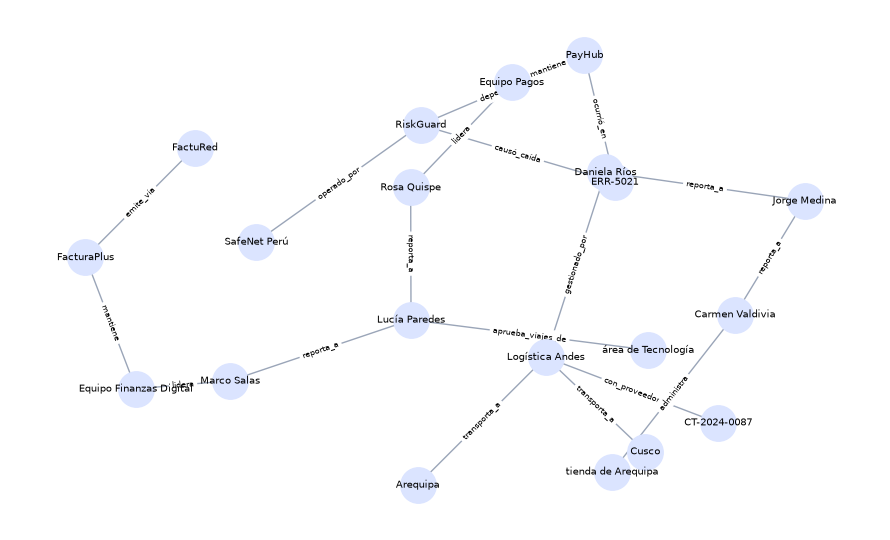

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

# El grafo: cada tripleta (sujeto, relación, objeto, doc_fuente) es una arista entre dos entidades.
# nx.Graph no tiene dirección: se puede recorrer en ambos sentidos. La arista guarda la relación y el documento fuente.
G = nx.Graph()
for s, rel, o, doc in TRIPLES:
    G.add_edge(s, o, relacion=rel, doc=doc)

print(G.number_of_nodes(), "entidades ·", G.number_of_edges(), "relaciones")

plt.figure(figsize=(9, 5.5))
pos = nx.spring_layout(G, seed=3, k=0.9)
nx.draw_networkx(G, pos, node_size=650, node_color="#dbe4ff", font_size=7, edge_color="#9aa5b8")
nx.draw_networkx_edge_labels(G, pos, edge_labels={(a, b): d["relacion"] for a, b, d in G.edges(data=True)}, font_size=6)
plt.axis("off"); plt.tight_layout(); plt.show()

## 2. Una pregunta, una cadena

Mira el camino que une `PayHub` con la persona que aprueba. Cada salto cita su documento.

In [5]:
# Camino más corto entre dos entidades: cada salto es una arista, y cada arista cita el documento del que sale.
camino = nx.shortest_path(G, "PayHub", "área de Tecnología")
for a, b in zip(camino, camino[1:]):
    d = G[a][b]
    print(f"{a}  ──{d['relacion']}──  {b}      [fuente: {d['doc']}]")

PayHub  ──mantiene──  Equipo Pagos      [fuente: E01]
Equipo Pagos  ──lidera──  Rosa Quispe      [fuente: E01]
Rosa Quispe  ──reporta_a──  Lucía Paredes      [fuente: E04]
Lucía Paredes  ──aprueba_viajes_de──  área de Tecnología      [fuente: E05]


## 3. Cuatro estrategias, dos grupos de preguntas

Estrategias:
- **texto top-3** y **texto top-6**: el híbrido calibrado del notebook 01.
- **grafo top-3**: parte de las entidades que nombra la pregunta, expande hasta 4 saltos y ordena los documentos por cercanía.
- **texto top-3 + grafo top-3**: hasta 6 documentos, por eso se compara contra *texto top-6* (mismo presupuesto de contexto).

Dos grupos de preguntas multi-hop:
- **Nombres explícitos**: la pregunta menciona las entidades que hay que encadenar («pasarela de pagos», «Rosa Quispe»…).
- **Puente oculto**: el documento intermedio casi no comparte palabras con la pregunta.
  *Transparencia: este segundo grupo lo añadí después de ver que el primero era demasiado fácil para el texto (cobertura de 94 % con texto top-6).*

Métrica: **cobertura** = fracción de los documentos necesarios que quedan en el contexto; **precisión** = qué parte del contexto era necesaria.

In [6]:
# Enlace de entidades: cómo se reconoce una entidad dentro de la pregunta. Está escrito a mano a propósito de estas
# preguntas, por eso este notebook es un TECHO: un LLM o un enlazador real se equivocaría más.
ALIAS = {  # en producción: un LLM o un enlazador de entidades; aquí, un diccionario
    "pasarela de pagos": "PayHub", "rosa quispe": "Rosa Quispe", "sistema de facturación": "FacturaPlus",
    "facturación": "FacturaPlus", "arequipa": "Arequipa", "cusco": "Cusco", "logística andes": "Logística Andes",
    "err-5021": "ERR-5021", "3 de septiembre": "ERR-5021",
}


def semillas(q):
    """Entidades del grafo que la pregunta menciona (los puntos de partida del recorrido)."""
    return [ent for alias, ent in ALIAS.items() if alias in q.lower() and ent in G]


def docs_por_grafo(q, saltos=4, k=3):
    """Expande desde las entidades de la pregunta; cada documento hereda la distancia de su arista más cercana."""
    mejor = {}                                       # documento → cuántos saltos hay desde la pregunta
    for s in semillas(q):
        # distancia (en saltos) desde la entidad de partida a cada entidad alcanzable, hasta `saltos` como máximo
        dist = nx.single_source_shortest_path_length(G, s, cutoff=saltos)
        for a, b, d in G.edges(data=True):
            if a in dist and b in dist:              # arista alcanzable: sus dos extremos están dentro del recorrido
                salto = min(dist[a], dist[b]) + 1    # distancia de la arista = salto más cercano + 1
                mejor[d["doc"]] = min(mejor.get(d["doc"], 99), salto)   # el documento hereda su arista más cercana
    # documentos ordenados del más cercano al más lejano; se devuelven los k primeros
    return [doc for doc, _ in sorted(mejor.items(), key=lambda x: x[1])][:k]


def docs_hibrido(q, k=3):
    """Los k mejores documentos del híbrido de texto (α = 0.7, el calibrado del notebook 01)."""
    return convexa(q, 0.7)[:k]


def medir(estrategia, preguntas):
    """`necesarios` es la clave de respuestas (el golden set): la estrategia NUNCA lo ve, solo recibe la pregunta `q`.
    Se usa únicamente aquí, para puntuar lo que la estrategia trajo."""
    cob, prec = [], []
    for q, necesarios, _ in preguntas:
        ctx = set(estrategia(q))                     # documentos que la estrategia puso en el contexto
        # cobertura = qué fracción de los necesarios llegó · precisión = qué fracción del contexto era necesaria
        cob.append(len(ctx & necesarios) / len(necesarios))
        prec.append(len(ctx & necesarios) / max(len(ctx), 1))
    return round(np.mean(cob), 2), round(np.mean(prec), 2)


# Las cuatro estrategias comparadas. «texto + grafo» junta ambas listas sin repetir (dict.fromkeys conserva el orden)
# y por eso tiene hasta 6 documentos: se compara contra «texto top-6», con el mismo presupuesto de contexto.
estrategias = {
    "texto top-3": lambda q: docs_hibrido(q, 3),
    "texto top-6": lambda q: docs_hibrido(q, 6),
    "grafo top-3": lambda q: docs_por_grafo(q, k=3),
    "texto top-3 + grafo top-3": lambda q: list(dict.fromkeys(docs_hibrido(q, 3) + docs_por_grafo(q, k=3))),
}
grupos = {"nombres explícitos": MULTIHOP, "puente oculto": MULTIHOP_PUENTE}
filas = {n: {(g, m): v for g, preg in grupos.items() for m, v in zip(["cobertura", "precisión"], medir(f, preg))}
         for n, f in estrategias.items()}
tabla = pd.DataFrame(filas).T
tabla

nombres explícitos           puente oculto          
                                   cobertura precisión     cobertura precisión
texto top-3                             0.83      0.67          0.67      0.56
texto top-6                             0.94      0.39          0.78      0.33
grafo top-3                             0.75      0.61          0.89      0.78
texto top-3 + grafo top-3               0.94      0.54          1.00      0.57

## 4. Dónde falla el texto

En el grupo de puente oculto, qué documentos necesarios **no** llegaron con cada estrategia:

In [7]:
for q, necesarios, esperado in MULTIHOP_PUENTE:
    print(f"\n» {q}\n  necesita {sorted(necesarios)} → respuesta: {esperado}")
    for n in ["texto top-6", "grafo top-3", "texto top-3 + grafo top-3"]:
        ctx = set(estrategias[n](q))
        print(f"   {n:28s} faltan: {sorted(necesarios - ctx) or '—'}")


» ¿Quién tiene que autorizar el viaje internacional del líder del equipo de facturación?
  necesita ['E02', 'E03', 'E05'] → respuesta: Lucía Paredes


   texto top-6                  faltan: ['E03']
   grafo top-3                  faltan: ['E05']
   texto top-3 + grafo top-3    faltan: —

» ¿Quién lidera el equipo que mantiene el sistema afectado el 3 de septiembre?
  necesita ['E01', 'E12'] → respuesta: Rosa Quispe
   texto top-6                  faltan: —
   grafo top-3                  faltan: —
   texto top-3 + grafo top-3    faltan: —

» ¿Quién es el superior de la persona que negocia con el proveedor que transporta a Cusco?
  necesita ['E08', 'E09', 'E10'] → respuesta: Jorge Medina
   texto top-6                  faltan: ['E10']
   grafo top-3                  faltan: —
   texto top-3 + grafo top-3    faltan: —


### Por qué faltan esos documentos (diagnóstico)

Cada estrategia falla por una razón distinta, y por eso se complementan:

**El texto pierde el documento «puente» (E03 y E10).** El híbrido de texto puntúa cada documento *por separado* contra la pregunta. Por ejemplo, E03 dice «Marco Salas reporta a la gerente de Tecnología, Lucía Paredes»: no comparte palabras con «¿Quién tiene que autorizar el viaje internacional del líder del equipo de facturación?». Su relación con la pregunta solo aparece **después de leer E02** (el equipo lo lidera Marco Salas), y ninguna similitud puede saberlo de antemano. Lo mismo pasa con E10 («Daniela Ríos reporta al gerente Jorge Medina»), que no menciona proveedor, transporte ni Cusco.

**El grafo pierde un documento lejano (E05).** `docs_por_grafo` ordena los documentos por distancia desde la entidad de la pregunta y se queda solo con 3. En la primera pregunta salen E02 y E07 (1 salto) y E03 (3 saltos); E05 está a 4 saltos, empatado con E04, y queda fuera del corte. El recorrido sí lo alcanza: lo descarta el `k=3`.

**Por qué la combinación llega a 1.00:** el grafo trae el puente que el texto no ve y el texto cubre lo que el grafo cortó. La pregunta 2 no falla en ninguna estrategia: ahí el texto ya alcanza.

**Cómo se podría corregir (no se prueba en este notebook):**

| Problema | Opciones | Costo |
|---|---|---|
| El texto no ve el puente | **Recuperar en dos pasos:** traer E02, leer «Marco Salas» y buscar de nuevo con ese nombre · **descomponer la pregunta** con un LLM («¿quién lidera el equipo?» → «¿a quién reporta?») · **enriquecer cada documento al indexarlo** («Marco Salas, líder de Finanzas Digital, reporta a…») · subir `k` y añadir un reranker (ayuda poco si el puente no comparte palabras) | más llamadas y latencia; depende de un LLM |
| El grafo corta la cadena | Subir `k` del grafo o devolver todo lo que esté a N saltos y reordenar · devolver los documentos del **camino entero** hasta la entidad que responde · combinar la distancia en el grafo con el puntaje del texto · mejorar el enlace de entidades (hoy es el diccionario `ALIAS`) | más contexto (y ruido) |

⚠️ Con solo 3 preguntas y un grafo escrito a mano, estas cifras son un **techo**, no una predicción: con un grafo extraído por un LLM habrá aristas faltantes y entidades duplicadas. Mide con tus propias preguntas.

In [8]:
cob = lambda n, g: tabla.loc[n, (g, "cobertura")]
assert cob("texto top-3 + grafo top-3", "puente oculto") > cob("texto top-6", "puente oculto"), "con puente oculto, texto + grafo debería cubrir más que el texto con el mismo presupuesto"
assert cob("texto top-6", "nombres explícitos") >= cob("grafo top-3", "nombres explícitos"), "con nombres explícitos el texto debería bastar"
print("Puente oculto → texto top-6:", cob("texto top-6", "puente oculto"), "· texto + grafo:", cob("texto top-3 + grafo top-3", "puente oculto"))
print("Nombres explícitos → texto top-6:", cob("texto top-6", "nombres explícitos"), "· texto + grafo:", cob("texto top-3 + grafo top-3", "nombres explícitos"))

Puente oculto → texto top-6: 0.78 · texto + grafo: 1.0
Nombres explícitos → texto top-6: 0.94 · texto + grafo: 0.94


### Lectura honesta

- Cuando la pregunta **nombra** todo lo que hay que encadenar, el texto basta y el grafo no aporta cobertura (sí algo de precisión).
- Cuando hay un **puente que la pregunta no nombra**, el recorrido del grafo encuentra documentos que ninguna similitud de texto va a traer.
- ⚠️ Este es un **techo**: el grafo está escrito a mano y el enlace de entidades usa un diccionario. Con extracción por LLM habrá aristas faltantes,
  entidades duplicadas y errores; el beneficio real será menor y hay que medirlo con tus documentos.

## Qué te llevas

- **GraphRAG paga cuando la pregunta es relacional** (quién reporta a quién, qué depende de qué, qué incidente vino de qué proveedor)
  y la respuesta exige encadenar documentos.
- **Cuesta**: extraer el grafo con un LLM (lento y con errores), mantenerlo actualizado y resolver entidades duplicadas.
  Si tus preguntas son de texto plano, un grafo es **sobre-ingeniería**.
- Un patrón práctico: **híbrido primero, grafo como complemento** para el subconjunto de preguntas relacionales (lo verás en el router del notebook 04).
- El grafo mejora la **trazabilidad**: cada salto cita su documento.

➡️ Siguiente: `04_router_y_sql.ipynb` — cómo decidir *automáticamente* qué método usar, y por qué los números no se buscan por similitud.

---
*Webinar «RAG para Soluciones Productivas» · Manuel Argüelles · datos 100 % sintéticos de «Andina Retail»: las cifras ilustran un criterio de decisión, no miden tu sistema. Mide siempre con tus propios datos.*